# 1. Environment Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")

print("Model Comparison Environment Ready!")

Model Comparison Environment Ready!


# 2. Loading Model Performance Metrics

In [2]:
comparison_df = pd.read_csv(
    DATA_DIR / "final_model_comparison.csv"
)

display(comparison_df)

,Model,MAE,RMSE,WMAPE (%)
0,Prophet,2805.365566,3575.991844,6.702144
1,Seasonal Naive,4341.660000,5117.310000,10.370000
2,"SARIMA(1,1,1)(1,1,1,7)",4450.620000,5361.630000,10.630000
3,"ARIMA(1,1,1)",5712.290000,7816.710000,13.650000


# 3. Updating Model Comparison
Adding xgboost performance

In [3]:
xgb_result = pd.DataFrame({
    "Model": ["XGBoost"],
    "MAE": [2615.99],
    "RMSE": [3452.68],
    "WMAPE (%)": [6.25]
})

comparison_df = pd.concat(
    [comparison_df, xgb_result],
    ignore_index=True
)

comparison_df = comparison_df.sort_values(
    by="WMAPE (%)"
).reset_index(drop=True)

display(comparison_df)

,Model,MAE,RMSE,WMAPE (%)
0,XGBoost,2615.990000,3452.680000,6.250000
1,Prophet,2805.365566,3575.991844,6.702144
2,Seasonal Naive,4341.660000,5117.310000,10.370000
3,"SARIMA(1,1,1)(1,1,1,7)",4450.620000,5361.630000,10.630000
4,"ARIMA(1,1,1)",5712.290000,7816.710000,13.650000


# 4. Saving Updated Model Comparison

In [4]:
comparison_df.to_csv(
    DATA_DIR / "final_model_comparison.csv",
    index=False
)

print("Final Model Comparison Saved Successfully!")

Final Model Comparison Saved Successfully!


# 5. Comparing Model Performance

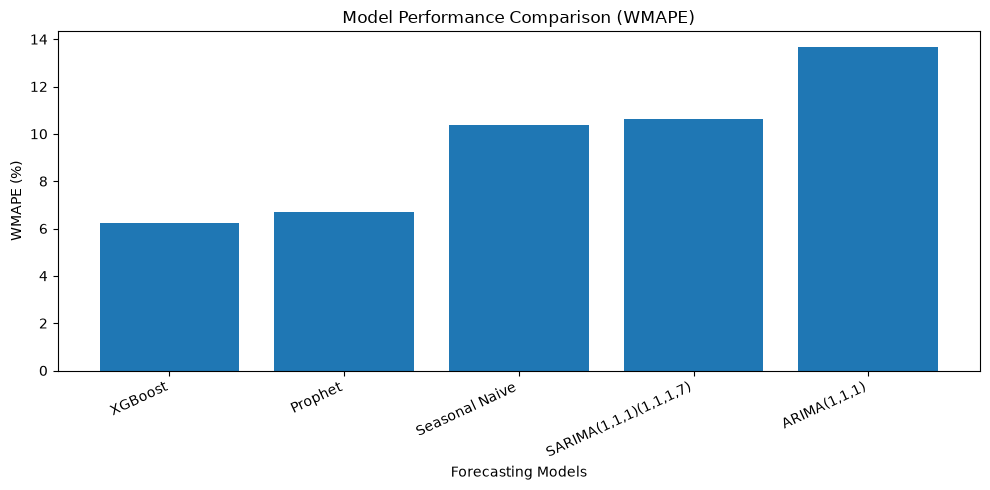

In [5]:
plt.figure(figsize=(10, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["WMAPE (%)"]
)

plt.title("Model Performance Comparison (WMAPE)")
plt.xlabel("Forecasting Models")
plt.ylabel("WMAPE (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

Lower WMAPE means better forecasting accuracy.

# 6. MAE and RMSE Model Comparison

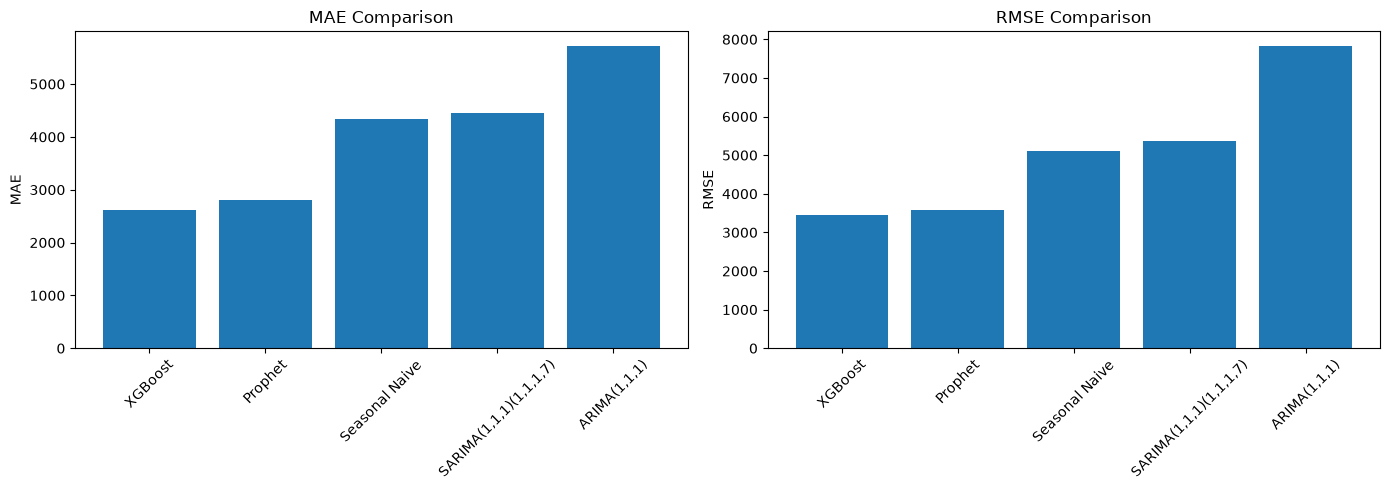

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(comparison_df["Model"], comparison_df["MAE"])
axes[0].set_title("MAE Comparison")
axes[0].set_ylabel("MAE")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(comparison_df["Model"], comparison_df["RMSE"])
axes[1].set_title("RMSE Comparison")
axes[1].set_ylabel("RMSE")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# 7. Selecting the Best Forecasting Model

In [7]:
best_model = comparison_df.loc[
    comparison_df["WMAPE (%)"].idxmin()
]

print("BEST FORECASTING MODEL")
print("----------------------")
print("Model:", best_model["Model"])
print("MAE:", round(best_model["MAE"], 2))
print("RMSE:", round(best_model["RMSE"], 2))
print("WMAPE:", round(best_model["WMAPE (%)"], 2), "%")

BEST FORECASTING MODEL
----------------------
Model: XGBoost
MAE: 2615.99
RMSE: 3452.68
WMAPE: 6.25 %


### Final Model Selection Observation

- XGBoost achieved the lowest MAE of 2615.99 among all five models.
- It also recorded the lowest RMSE of 3452.68.
- Its WMAPE of 6.25% was the best among the evaluated models.
- Prophet secured the second position with a WMAPE of 6.70%.
- Seasonal Naive, SARIMA and ARIMA recorded comparatively higher forecasting errors.

Based on the 90-day test evaluation, XGBoost was selected as the best-performing forecasting model.

The selected model forecasts aggregate daily sales across the dataset, not individual product-level demand.

# 8. Exporting Final Model Results

In [8]:
comparison_df.to_csv(
    DATA_DIR / "model_comparison_results.csv",
    index=False
)

print("Final Results Exported Successfully!")
print("Selected Model:", best_model["Model"])
print("Total Models Compared:", len(comparison_df))

Final Results Exported Successfully!
Selected Model: XGBoost
Total Models Compared: 5
